           Tiempo entre llegadas  Tiempo de servicio  Tiempo en cola
n                          99.00              100.00          100.00
media                      81.01              155.86         4064.69
mediana                    57.00              163.00         4273.00
desv_est                   79.22               51.41         2235.62
CV                          0.98                0.33            0.55
min                         1.00               61.00            0.00
Q1                         18.50              110.75         2306.50
Q3                        117.50              199.75         6091.50
max                       300.00              239.00         7640.00
asimetria                   1.30               -0.15           -0.22
curtosis                    1.02               -1.24           -1.17
outliers                    6.00                0.00            0.00

rho = 1.92
Cola media = 4065 s | TIS medio = 4221 s
Cola consistente con llegadas y servicio: True


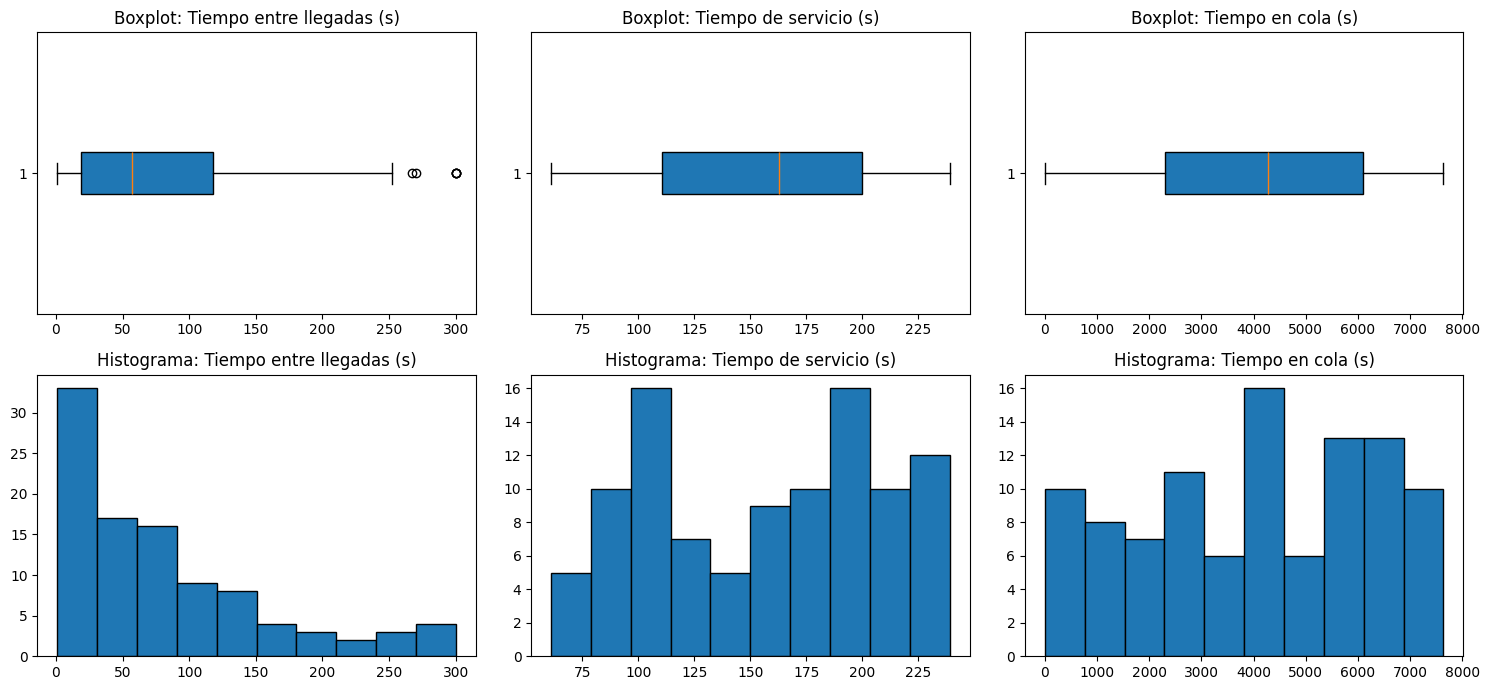

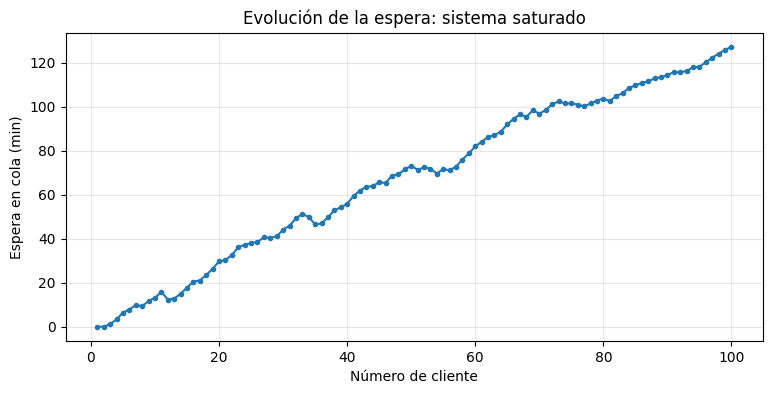

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from google.colab import files
# files.upload()   # sube los 3 .txt

arch = {'Tiempo entre llegadas': 'tiempo entre llegadas (1).txt',
        'Tiempo de servicio':    'tiempo de servicio (1).txt',
        'Tiempo en cola':        'tiempo en cola (1).txt'}
datos = {k: pd.read_csv(v, header=None)[0] for k, v in arch.items()}

# Tabla descriptiva
filas = {}
for k, s in datos.items():
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    filas[k] = {'n': len(s), 'media': s.mean(), 'mediana': s.median(),
                'desv_est': s.std(), 'CV': s.std()/s.mean(),
                'min': s.min(), 'Q1': q1, 'Q3': q3, 'max': s.max(),
                'asimetria': s.skew(), 'curtosis': s.kurt(),
                'outliers': ((s < q1-1.5*iqr) | (s > q3+1.5*iqr)).sum()}
print(pd.DataFrame(filas).round(2))

# Indicadores reales
a = datos['Tiempo entre llegadas'].values
s = datos['Tiempo de servicio'].values
w = datos['Tiempo en cola'].values
print(f"\nrho = {s.mean()/a.mean():.2f}")
print(f"Cola media = {w.mean():.0f} s | TIS medio = {(w+s).mean():.0f} s")

# Verificación: la cola calculada con llegadas y servicio
wl = [0.0]
for n in range(len(a)):
    wl.append(max(0, wl[-1] + s[n] - a[n]))
print("Cola consistente con llegadas y servicio:", np.allclose(wl, w))

# Gráficos
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, (k, x) in enumerate(datos.items()):
    ax[0, i].boxplot(x, vert=False, patch_artist=True); ax[0, i].set_title(f'Boxplot: {k} (s)')
    ax[1, i].hist(x, bins=10, edgecolor='k');           ax[1, i].set_title(f'Histograma: {k} (s)')
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(w)+1), w/60, marker='o', ms=3)
plt.xlabel('Número de cliente'); plt.ylabel('Espera en cola (min)')
plt.title('Evolución de la espera: sistema saturado'); plt.grid(alpha=.3); plt.show()